# Preference likelihood with a known noise level

The preference model of the package fixes the noise on each utility at 1: $P(a \succ b) = \Phi\big((u(a)-u(b))/\sqrt2\big)$.
My simulated decision maker has noise $\sigma_{dm} = 0.5$ on each utility, so its true win probability is $\Phi\big((u(a)-u(b))/(\sqrt2\,\sigma_{dm})\big)$.
Here, **only in this notebook**, the likelihood gets a known noise level $\sigma$ (the package is not modified), and the Copeland score becomes
$C(x) = \frac1M\sum_k \Phi\big(\Delta m / \sqrt{2\sigma^2 + \Delta v}\big)$ (GPML eq. 3.82 with scale $\sqrt2\,\sigma$).
It is compared with the current model ($\sigma = 1$) on the same noisy answers, for several noise levels of the decision maker ($\sigma_{dm}$ = 0.5, 2, 4).

In [1]:
import math
import sys, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch
from botorch.fit import fit_gpytorch_mll
from botorch.models import PairwiseGP
from botorch.models.likelihoods.pairwise import PairwiseProbitLikelihood
from botorch.models.pairwise_gp import PairwiseLaplaceMarginalLogLikelihood
from botorch.models.transforms.input import Normalize
from scipy.stats import norm, spearmanr

for folder in (Path.cwd(), Path.cwd().parent):
    if (folder / "BOproj").is_dir():
        sys.path.insert(0, str(folder))
        break

from BOproj.benchmarks import ROSEN_BOUNDS, u_polynomial
from BOproj.bo_loop import initial_design, seeded
from BOproj.copeland import SoftCopeland
from BOproj.gp import PreferenceGP
from BOproj.gp_utils import DTYPE, as_2d, bounds_tensor, format_comparisons, make_kernel

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

n_landmarks = 64
dm_noise_levels = (0.5, 2.0, 4.0)        # noise sd of the simulated decision maker on each utility
comparison_counts = (5, 10, 30, 300)
answer_seeds = range(5)
figure_counts = (10, 30)
CURRENT_MODEL = "sigma = 1 (current)"


class NoisyPairwiseLabeler:
    """DM with Gaussian noise on each utility: a wins iff u(a) + noise_a > u(b) + noise_b, noise ~ N(0, sigma^2)."""

    def __init__(self, utility, sigma, seed=0):
        self.utility, self.sigma, self.rng = utility, sigma, np.random.default_rng(seed)

    def __call__(self, xa, xb):
        noise = self.sigma * self.rng.standard_normal((2, len(xa)))
        return self.utility(xa) + noise[0] > self.utility(xb) + noise[1]


BUKIN_BOUNDS = [[-15.0, -5.0], [-3.0, 3.0]]


def u_bukin(X):
    """Accept a disc of radius 1.5 around (-7, 0.5), which lies on the ridge; the minimum (-10, 1) is rejected."""
    return 1 - ((X[:, 0] + 7) ** 2 + (X[:, 1] - 0.5) ** 2) / 1.5 ** 2


PROBLEMS = {"Rosenbrock": dict(bounds=ROSEN_BOUNDS, utility=u_polynomial),
            "Bukin N.6": dict(bounds=BUKIN_BOUNDS, utility=u_bukin)}


def noise_aware_model_label(noise):
    return f"sigma = {noise} (noise-aware)"


def noisy_answers(problem, n_comparisons, seed, noise):
    """n_comparisons noisy DM answers about random pairs of 30 lhs designs: (first, second, first_wins)."""
    designs = initial_design(problem["bounds"], 30, "lhs", seed=7)
    rng = np.random.default_rng(seed)
    first = rng.integers(0, len(designs), n_comparisons)
    second = (first + rng.integers(1, len(designs), n_comparisons)) % len(designs)
    first_wins = NoisyPairwiseLabeler(problem["utility"], noise, seed=seed)(designs[first], designs[second])
    return designs[first], designs[second], first_wins

/home/fabyk/THESIS/BOproj/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. A probit likelihood with a known noise level, and the Copeland score that goes with it

In [2]:
class NoisyPairwiseProbitLikelihood(PairwiseProbitLikelihood):
    """P(a beats b) = Phi((u(a) - u(b)) / (sqrt(2) * noise_scale)): each utility carries Gaussian noise of standard
    deviation noise_scale (1 is BoTorch's PairwiseProbitLikelihood).  Every sqrt(2) of the parent becomes
    sqrt(2) * noise_scale: in the z score, in the gradient, and (the square) in the Hessian, where 2 -> 2 noise_scale^2."""

    def __init__(self, noise_scale):
        super().__init__()
        self.noise_scale = noise_scale

    def _calc_z(self, utility, D):
        scaled_utility = (utility / (math.sqrt(2) * self.noise_scale)).unsqueeze(-1)
        z = D.to(scaled_utility) @ scaled_utility
        return z.clamp(-self._zlim, self._zlim).squeeze(-1)

    def negative_log_gradient_sum(self, utility, D):
        z = self._calc_z(utility, D)
        _, _, hazard = self._calc_z_derived(z)
        return ((hazard / (math.sqrt(2) * self.noise_scale)).unsqueeze(-2) @ (-D)).squeeze(-2)

    def negative_log_hessian_sum(self, utility, D):
        D_transposed = D.transpose(-1, -2)
        z = self._calc_z(utility, D)
        _, _, hazard = self._calc_z_derived(z)
        factor = hazard * (hazard + z) / (2 * self.noise_scale ** 2)
        return D_transposed * factor.unsqueeze(-2).expand(*D_transposed.size()) @ D


class NoisyPreferenceGP(PreferenceGP):
    """PreferenceGP (probit) fitted with NoisyPairwiseProbitLikelihood: same kernel, input transform and marginal
    likelihood as PreferenceGP.fit, only the likelihood differs."""

    def __init__(self, bounds, noise_scale, kernel="matern52", normalize_x=True):
        super().__init__(bounds=bounds, kernel=kernel, link="probit", normalize_x=normalize_x)
        self.noise_scale = noise_scale

    def fit(self, xa, xb, a_wins=None):
        designs, comparisons = format_comparisons(as_2d(xa), as_2d(xb), a_wins)
        self.d = designs.shape[1]
        input_transform = Normalize(d=self.d, bounds=bounds_tensor(self.bounds, self.d)) if self.normalize_x else None
        self.model = PairwiseGP(torch.as_tensor(designs, dtype=DTYPE), torch.as_tensor(comparisons, dtype=torch.long),
                                likelihood=NoisyPairwiseProbitLikelihood(self.noise_scale),
                                covar_module=make_kernel(self.kernel, self.d, True), input_transform=input_transform)
        self.mll = PairwiseLaplaceMarginalLogLikelihood(self.model.likelihood, self.model)
        fit_gpytorch_mll(self.mll)
        self.model.eval()
        self.train_X, self.comparisons = designs, comparisons
        return self


class NoisyAwareSoftCopeland(SoftCopeland):
    """SoftCopeland with the preference noise in the closed form: C(x) = mean_k Phi(dm / sqrt(2 sigma^2 + dv)).
    prepare() is inherited; only the last lines of __call__ change (2 -> 2 noise_scale^2).  Probit link only."""

    def __init__(self, preference_gp, landmarks, noise_scale):
        super().__init__(preference_gp, landmarks)
        self.noise_scale = noise_scale

    def __call__(self, X):
        if not self.is_prepared:
            raise RuntimeError("call prepare() first")
        model = self.preference_gp.model
        X = model.transform_inputs(torch.as_tensor(X, dtype=DTYPE))
        data_covariance = model.covar_module(X, self._train_inputs).to_dense()
        mean = (data_covariance @ self._weights).squeeze(-1) + model._prior_mean(X)
        variance = model.covar_module(X, diag=True) - (data_covariance * (data_covariance @ self._link_to_data.T)).sum(-1)
        landmark_covariance = (model.covar_module(X, self._landmarks).to_dense()
                               - data_covariance @ self._landmark_projection)
        diff_mean = mean[:, None] - self._landmark_mean[None, :]
        diff_variance = (variance[:, None] + self._landmark_variance[None, :] - 2 * landmark_covariance).clamp_min(0)
        return torch.special.ndtr(diff_mean / torch.sqrt(2 * self.noise_scale ** 2 + diff_variance)).mean(dim=1)

## 2. Checks

In [3]:
def random_comparison_matrix(n_items, n_comparisons, generator):
    """D of BoTorch: row j has +1 at the winner and -1 at the loser of comparison j."""
    D = torch.zeros(n_comparisons, n_items, dtype=DTYPE)
    for row in range(n_comparisons):
        winner, loser = torch.randperm(n_items, generator=generator)[:2]
        D[row, winner], D[row, loser] = 1.0, -1.0
    return D


def check_likelihood_matches_botorch(n_items=8, n_comparisons=14):
    """sigma = 1: probability, gradient and Hessian of the new likelihood against BoTorch's."""
    generator = torch.Generator().manual_seed(0)
    D = random_comparison_matrix(n_items, n_comparisons, generator)
    utility = 0.8 * torch.randn(n_items, dtype=DTYPE, generator=generator)
    botorch_likelihood, new_likelihood = PairwiseProbitLikelihood(), NoisyPairwiseProbitLikelihood(1.0)
    return {"probability": float((botorch_likelihood.p(utility, D) - new_likelihood.p(utility, D)).abs().max()),
            "gradient": float((botorch_likelihood.negative_log_gradient_sum(utility, D)
                               - new_likelihood.negative_log_gradient_sum(utility, D)).abs().max()),
            "Hessian": float((botorch_likelihood.negative_log_hessian_sum(utility, D)
                              - new_likelihood.negative_log_hessian_sum(utility, D)).abs().max())}


def check_derivatives_with_autograd(noise_scale, n_items=8, n_comparisons=14):
    """Gradient and Hessian of the negative log-likelihood against torch.autograd (z kept inside the +-3 clamp)."""
    generator = torch.Generator().manual_seed(1)
    D = random_comparison_matrix(n_items, n_comparisons, generator)
    utility = 0.4 * torch.randn(n_items, dtype=DTYPE, generator=generator)
    likelihood = NoisyPairwiseProbitLikelihood(noise_scale)
    largest_z = float((D @ utility).abs().max() / (math.sqrt(2) * noise_scale))
    negative_log_likelihood = lambda values: -likelihood.log_p(values, D).sum()
    autograd_gradient = torch.autograd.functional.jacobian(negative_log_likelihood, utility)
    autograd_hessian = torch.autograd.functional.hessian(negative_log_likelihood, utility)
    return {"largest |z|": largest_z,
            "gradient": float((likelihood.negative_log_gradient_sum(utility, D) - autograd_gradient).abs().max()),
            "Hessian": float((likelihood.negative_log_hessian_sum(utility, D) - autograd_hessian).abs().max())}


def check_fit_and_copeland_match_package(problem, n_comparisons=30):
    """sigma = 1: the fitted utility and the Copeland score against PreferenceGP and SoftCopeland, same seed."""
    answers = noisy_answers(problem, n_comparisons, seed=0, noise=1.0)
    with seeded(0):
        package_gp = PreferenceGP(bounds=problem["bounds"], link="probit").fit(*answers)
    with seeded(0):
        new_gp = NoisyPreferenceGP(problem["bounds"], noise_scale=1.0).fit(*answers)
    box = np.asarray(problem["bounds"])
    grid_1, grid_2 = np.meshgrid(np.linspace(*box[0], 20), np.linspace(*box[1], 20))
    grid_points = np.c_[grid_1.ravel(), grid_2.ravel()]
    landmarks = initial_design(problem["bounds"], n_landmarks, "random", seed=0)
    with torch.no_grad():
        package_scores = SoftCopeland(package_gp, landmarks).prepare()(grid_points).numpy()
        new_scores = NoisyAwareSoftCopeland(new_gp, landmarks, 1.0).prepare()(grid_points).numpy()
    return {"fitted utility": float((package_gp.model.utility - new_gp.model.utility).abs().max()),
            "Copeland score": float(np.abs(package_scores - new_scores).max())}


print("sigma = 1, new likelihood vs BoTorch (largest absolute difference):", check_likelihood_matches_botorch())
for noise_scale in (1.0, 0.5):
    print(f"sigma = {noise_scale}, analytic derivatives vs autograd:", check_derivatives_with_autograd(noise_scale))
for name, problem in PROBLEMS.items():
    print(f"sigma = 1, fit and Copeland vs the package, {name}:", check_fit_and_copeland_match_package(problem))

sigma = 1, new likelihood vs BoTorch (largest absolute difference): {'probability': 0.0, 'gradient': 0.0, 'Hessian': 0.0}
sigma = 1.0, analytic derivatives vs autograd: {'largest |z|': 0.8824650329673704, 'gradient': 8.881784197001252e-16, 'Hessian': 1.7763568394002505e-15}
sigma = 0.5, analytic derivatives vs autograd: {'largest |z|': 1.7649300659347409, 'gradient': 1.7763568394002505e-15, 'Hessian': 4.440892098500626e-15}
sigma = 1, fit and Copeland vs the package, Rosenbrock: {'fitted utility': 0.0, 'Copeland score': 0.0}
sigma = 1, fit and Copeland vs the package, Bukin N.6: {'fitted utility': 0.0, 'Copeland score': 0.0}


## 3. Current model (σ = 1) against the noise-aware model (σ = 0.5)

In [4]:
def build_evaluation_set(problem, noise):
    """Fixed per problem: landmarks, a 50 x 50 grid, 2000 random pairs, and the decision maker's true quantities."""
    box = np.asarray(problem["bounds"])
    grid_1, grid_2 = np.meshgrid(np.linspace(*box[0], 50), np.linspace(*box[1], 50))
    grid_points = np.c_[grid_1.ravel(), grid_2.ravel()]
    landmarks = initial_design(problem["bounds"], n_landmarks, "random", seed=0)
    first_designs = initial_design(problem["bounds"], 2000, "random", seed=11)
    second_designs = initial_design(problem["bounds"], 2000, "random", seed=12)
    utility = problem["utility"]
    true_probability = norm.cdf((utility(first_designs) - utility(second_designs)) / (np.sqrt(2) * noise))
    true_scores = norm.cdf((utility(grid_points)[:, None] - utility(landmarks)[None, :]) / (np.sqrt(2) * noise)).mean(axis=1)
    return dict(grid_points=grid_points, landmarks=landmarks, first_designs=first_designs, second_designs=second_designs,
                true_probability=true_probability, true_scores=true_scores, widths=box[:, 1] - box[:, 0])


def fit_both_models(problem, answers, n_comparisons, seed, noise):
    """The package's PreferenceGP (sigma fixed at 1) and the noise-aware one (sigma = the decision maker's noise), on the same answers."""
    first, second, first_wins = (part[:n_comparisons] for part in answers)
    with seeded(seed):
        current = PreferenceGP(bounds=problem["bounds"], link="probit").fit(first, second, first_wins)
    with seeded(seed):
        noise_aware = NoisyPreferenceGP(problem["bounds"], noise_scale=noise).fit(first, second, first_wins)
    return {CURRENT_MODEL: (current, 1.0), noise_aware_model_label(noise): (noise_aware, noise)}


def predicted_win_probability(preference_gp, noise_scale, first_designs, second_designs):
    """Phi(dm / sqrt(2 noise_scale^2 + dv)) for each pair, from the joint posterior of the two utilities."""
    pairs = torch.as_tensor(np.stack([first_designs, second_designs], axis=1), dtype=DTYPE)
    with torch.no_grad():
        posterior = preference_gp.model.posterior(pairs)
        mean = posterior.mean.reshape(-1, 2).numpy()
        covariance = posterior.mvn.covariance_matrix.numpy()
    difference_variance = covariance[:, 0, 0] + covariance[:, 1, 1] - 2 * covariance[:, 0, 1]
    return norm.cdf((mean[:, 0] - mean[:, 1]) / np.sqrt(2 * noise_scale ** 2 + difference_variance))


def learned_copeland_scores(preference_gp, noise_scale, evaluation):
    """The package's SoftCopeland for the current model, NoisyAwareSoftCopeland for the noise-aware one."""
    landmarks, grid_points = evaluation["landmarks"], evaluation["grid_points"]
    if noise_scale == 1.0:
        scorer = SoftCopeland(preference_gp, landmarks)
    else:
        scorer = NoisyAwareSoftCopeland(preference_gp, landmarks, noise_scale)
    with torch.no_grad():
        return scorer.prepare()(grid_points).numpy()


def calibration_metrics(predicted, evaluation):
    true_probability = evaluation["true_probability"]
    return {"calibration_error": float(np.abs(predicted - true_probability).mean()),
            "calibration_correlation": float(np.corrcoef(predicted, true_probability)[0, 1])}


def copeland_metrics(learned_scores, evaluation):
    true_scores, grid_points = evaluation["true_scores"], evaluation["grid_points"]
    offset = (grid_points[learned_scores.argmax()] - grid_points[true_scores.argmax()]) / evaluation["widths"]
    return {"copeland_rank_correlation": float(spearmanr(learned_scores, true_scores)[0]),
            "copeland_error": float(np.abs(learned_scores - true_scores).mean()),
            "argmax_distance": float(np.linalg.norm(offset))}


def utility_metrics(preference_gp, problem):
    """Slope and correlation of the fitted utility against the true one, at the training designs."""
    model = preference_gp.model
    fitted = model.utility.detach().numpy()
    true_utility = problem["utility"](model.datapoints.detach().numpy())
    fitted_centered, true_centered = fitted - fitted.mean(), true_utility - true_utility.mean()
    return {"utility_slope": float((fitted_centered * true_centered).sum() / (true_centered ** 2).sum()),
            "utility_correlation": float(np.corrcoef(fitted, true_utility)[0, 1])}


def run_comparison(noise):
    """One row of metrics per (problem, number of comparisons, seed of the answers, model); grids kept for seed 0."""
    rows, figure_scores = [], {}
    for name, problem in PROBLEMS.items():
        evaluation = build_evaluation_set(problem, noise)
        for seed in answer_seeds:
            answers = noisy_answers(problem, max(comparison_counts), seed, noise)
            for n_comparisons in comparison_counts:
                scores_of_model = {}
                for model_name, (preference_gp, noise_scale) in fit_both_models(problem, answers, n_comparisons, seed, noise).items():
                    predicted = predicted_win_probability(preference_gp, noise_scale, evaluation["first_designs"], evaluation["second_designs"])
                    learned_scores = learned_copeland_scores(preference_gp, noise_scale, evaluation)
                    scores_of_model[model_name] = learned_scores
                    rows.append(dict(problem=name, comparisons=n_comparisons, seed=seed, model=model_name,
                                     **calibration_metrics(predicted, evaluation), **copeland_metrics(learned_scores, evaluation),
                                     **utility_metrics(preference_gp, problem)))
                if seed == 0 and n_comparisons in figure_counts:
                    figure_scores[(name, n_comparisons)] = (evaluation, scores_of_model)
    return rows, figure_scores


results_by_noise = {noise: run_comparison(noise) for noise in dm_noise_levels}

KeyboardInterrupt: 

In [ ]:
METRICS = [("calibration_error", "win-prob. error"), ("calibration_correlation", "win-prob. corr."),
           ("copeland_rank_correlation", "Copeland rank corr."), ("copeland_error", "Copeland |diff|"),
           ("argmax_distance", "argmax distance"), ("utility_slope", "utility slope"), ("utility_correlation", "utility corr.")]


def print_summary_table(rows, noise):
    """Mean (std over the seeds of the answers) of every metric, per problem, number of comparisons and model."""
    print(f"{'problem':11s} {'cmp':>4s} {'model':27s}" + "".join(f"{label:>22s}" for _, label in METRICS))
    for name in PROBLEMS:
        for n_comparisons in comparison_counts:
            for model_name in (CURRENT_MODEL, noise_aware_model_label(noise)):
                selected = [row for row in rows if (row["problem"], row["comparisons"], row["model"]) == (name, n_comparisons, model_name)]
                cells = [f"{np.mean([row[key] for row in selected]):8.3f} ± {np.std([row[key] for row in selected]):5.3f}" for key, _ in METRICS]
                print(f"{name:11s} {n_comparisons:4d} {model_name:27s}" + "".join(f"{cell:>22s}" for cell in cells))
        print()


for noise, (rows, _) in results_by_noise.items():
    print(f"=== decision-maker noise sigma_dm = {noise} ===")
    print_summary_table(rows, noise)

=== decision-maker noise sigma_dm = 0.5 ===
problem      cmp model                             win-prob. error       win-prob. corr.   Copeland rank corr.       Copeland |diff|       argmax distance         utility slope         utility corr.
Rosenbrock     5 sigma = 1 (current)                 0.398 ± 0.063         0.708 ± 0.074         0.820 ± 0.089         0.194 ± 0.040         0.229 ± 0.136         0.099 ± 0.099         0.819 ± 0.103
Rosenbrock     5 sigma = 0.5 (noise-aware)           0.398 ± 0.063         0.708 ± 0.074         0.820 ± 0.089         0.194 ± 0.040         0.229 ± 0.136         0.049 ± 0.049         0.819 ± 0.103
Rosenbrock    10 sigma = 1 (current)                 0.303 ± 0.087         0.808 ± 0.064         0.890 ± 0.055         0.136 ± 0.054         0.173 ± 0.081         0.260 ± 0.138         0.883 ± 0.070
Rosenbrock    10 sigma = 0.5 (noise-aware)           0.303 ± 0.087         0.808 ± 0.064         0.891 ± 0.055         0.136 ± 0.054         0.173 ± 0.081      

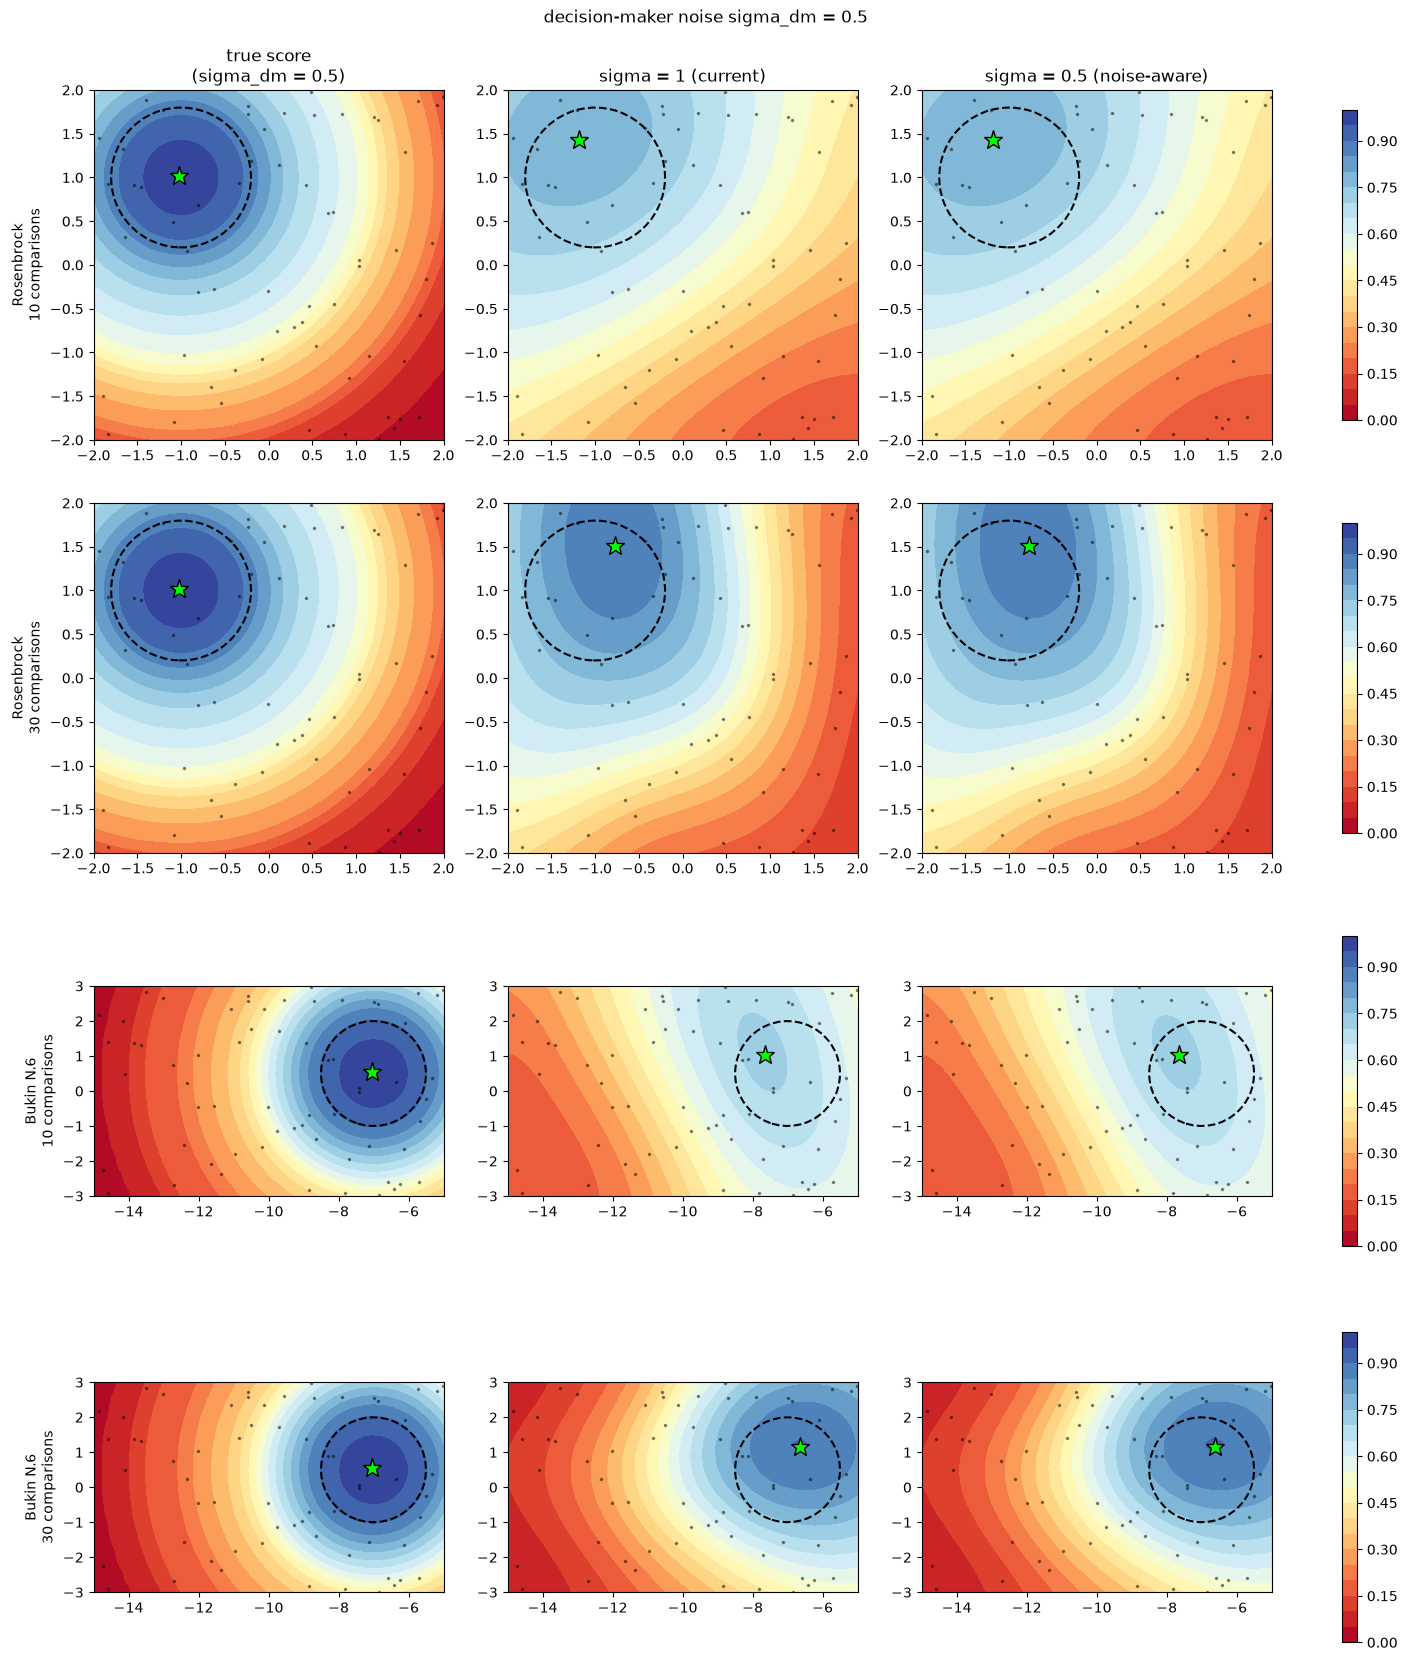

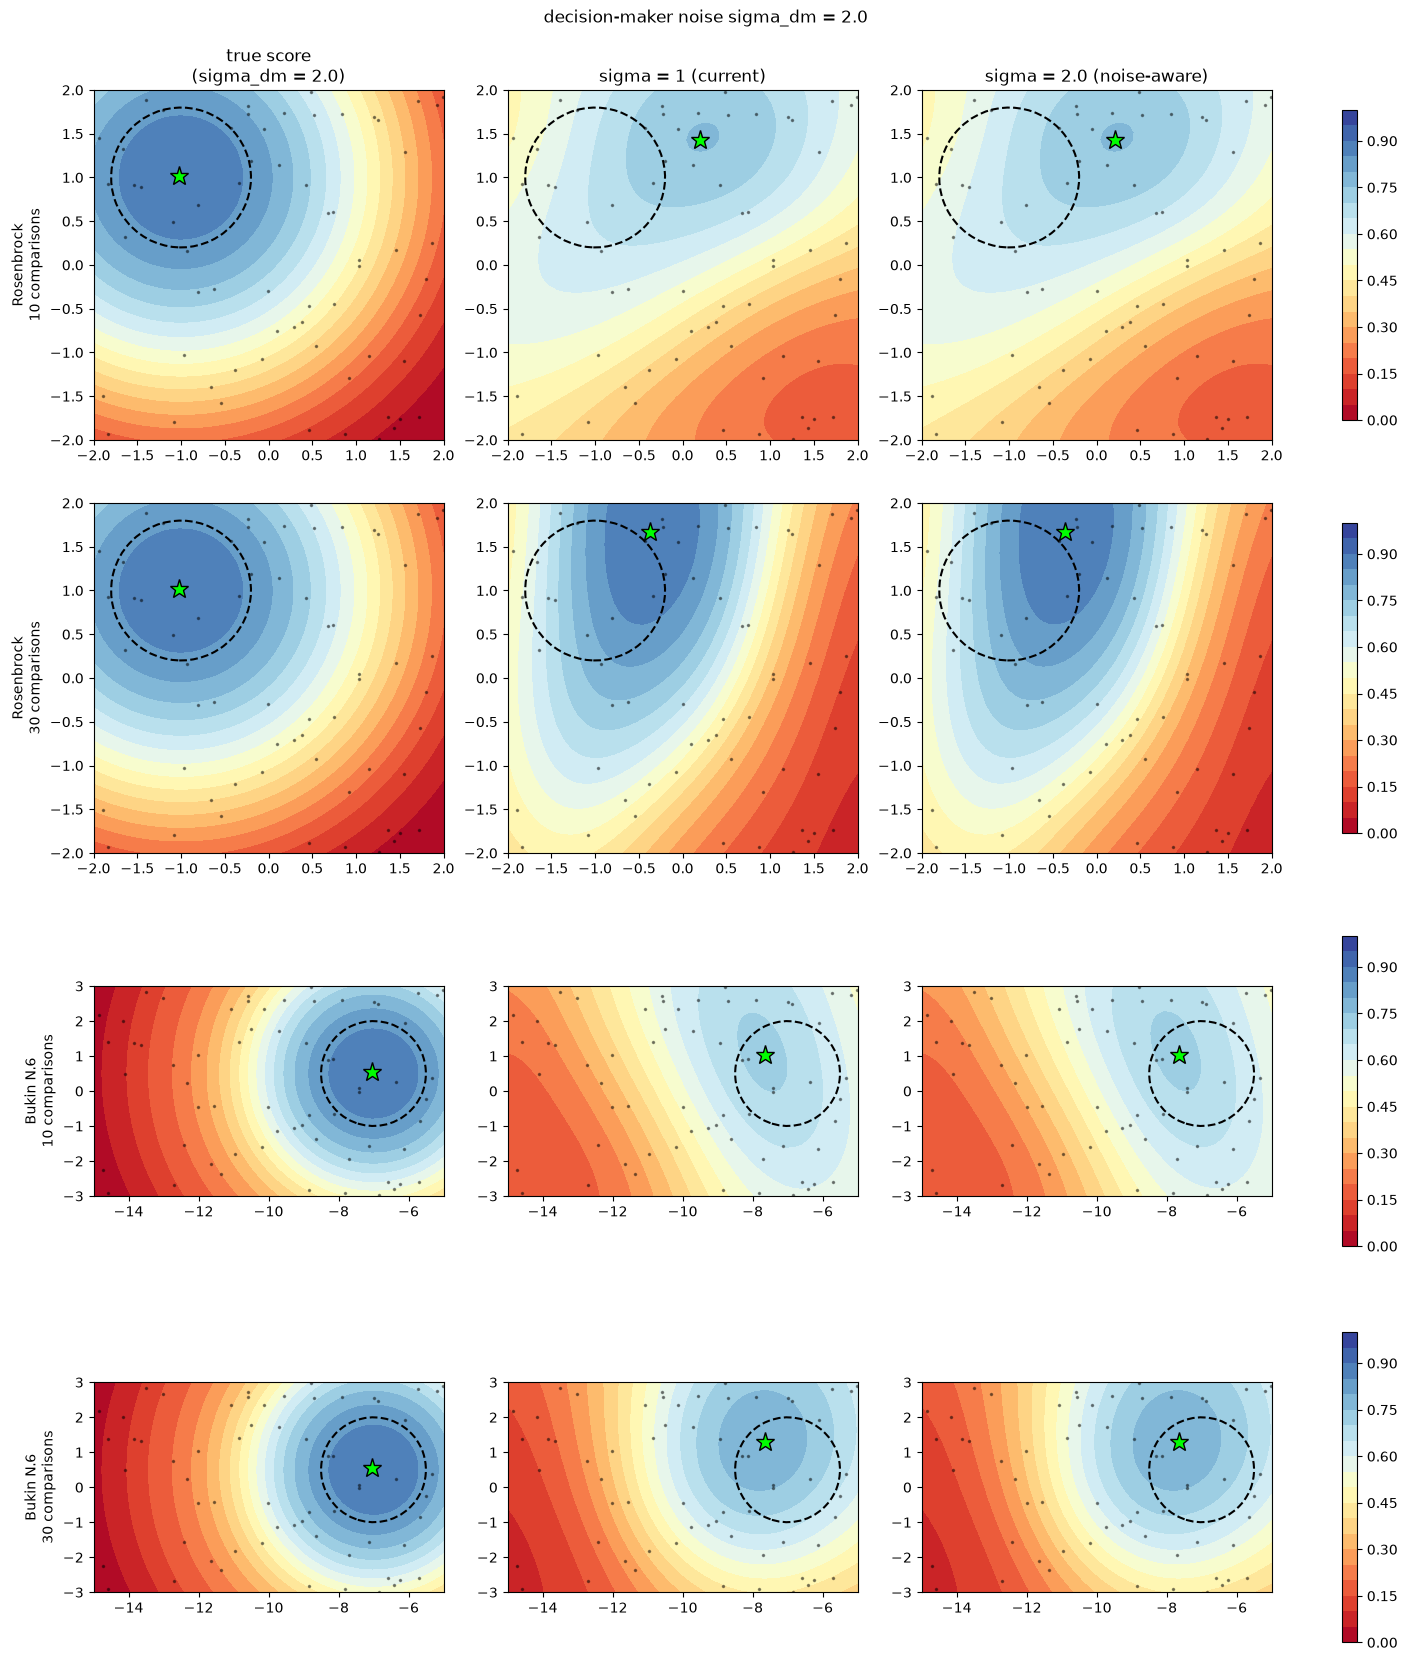

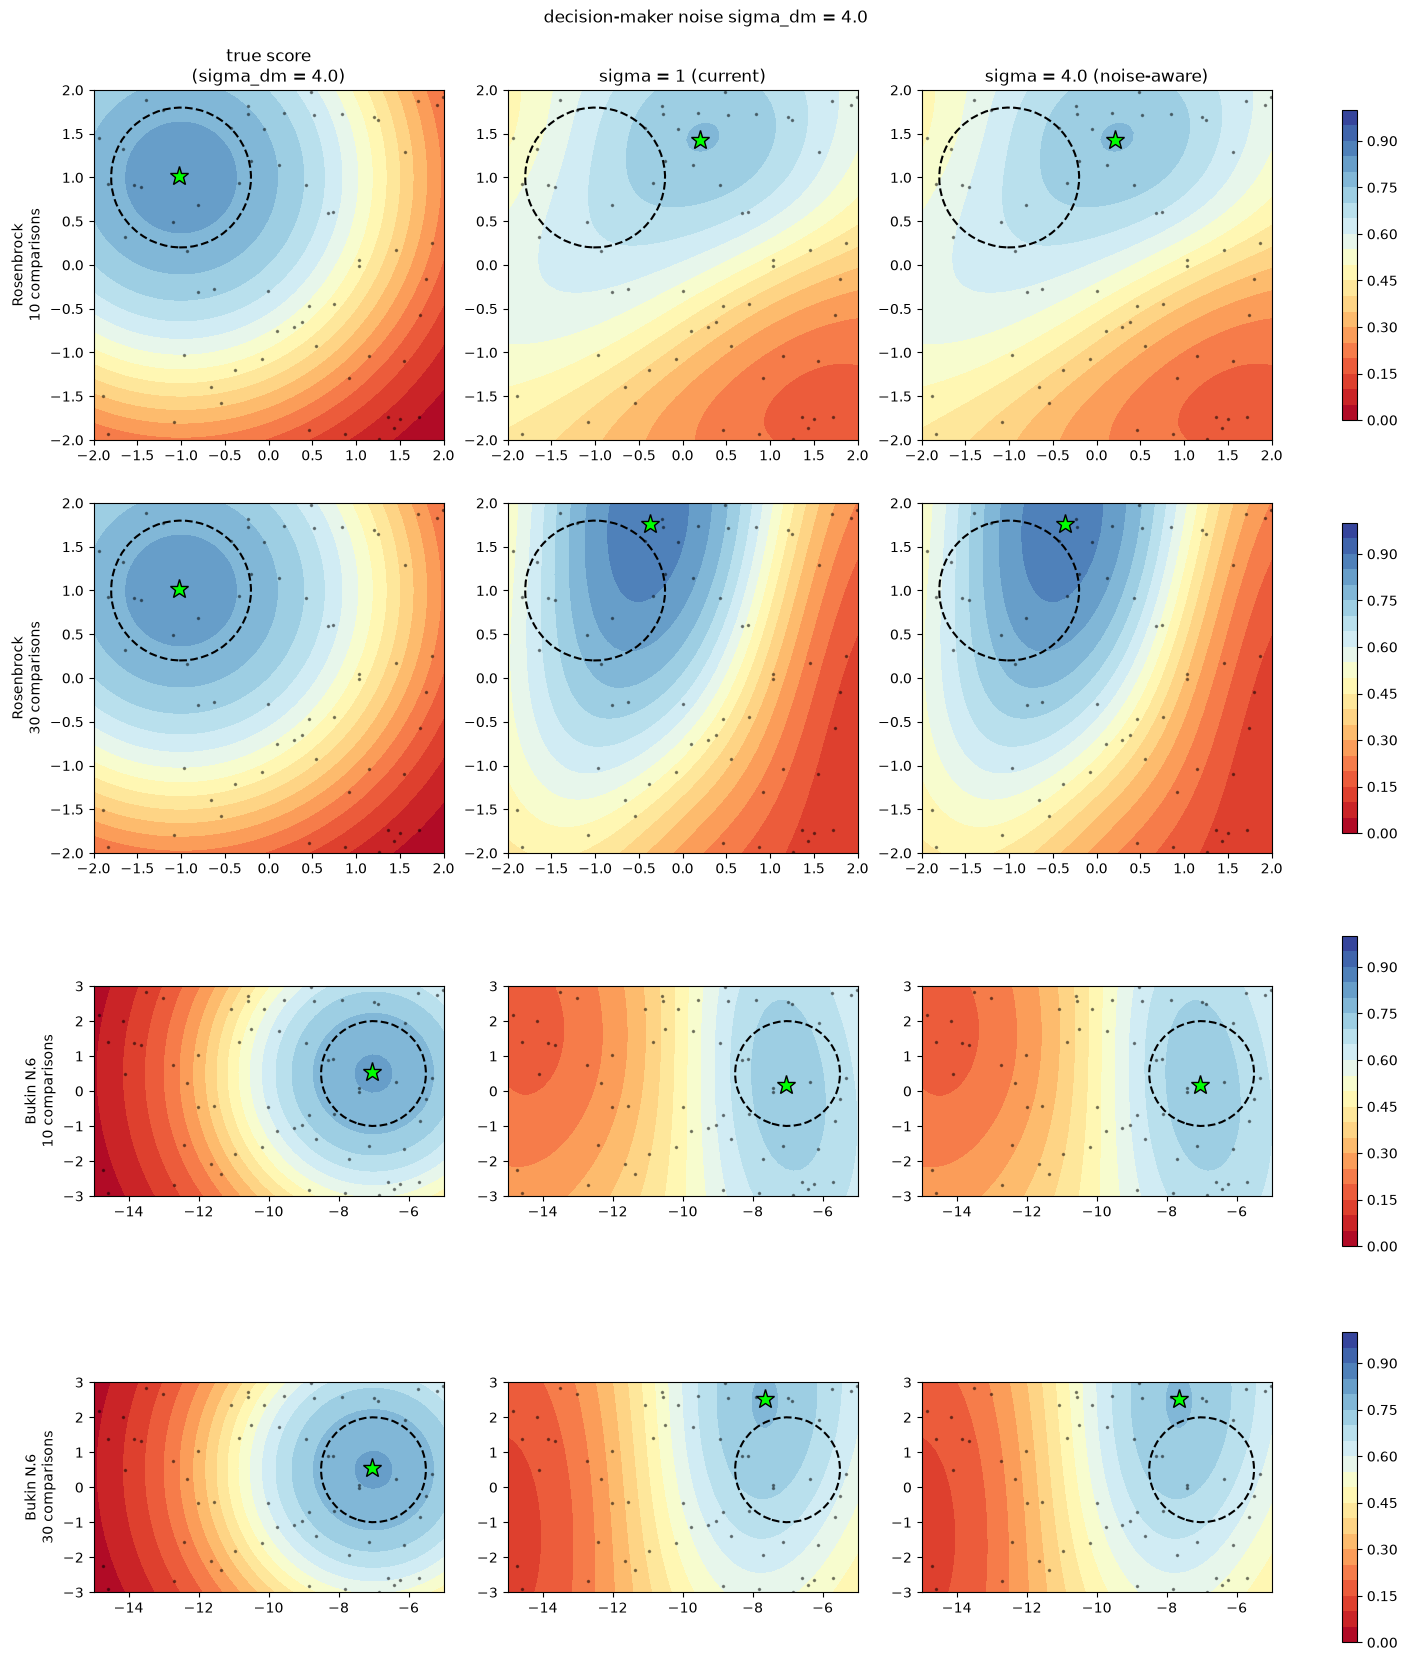

In [ ]:
def plot_copeland_comparison(figure_scores, noise):
    """Rows: problem x number of comparisons (answers of seed 0). Columns: the true score (sigma_dm), the current model, the noise-aware model."""
    fig, axes = plt.subplots(len(figure_scores), 3, figsize=(14, 4.2 * len(figure_scores)), layout="constrained")
    for row_index, (row_axes, ((name, n_comparisons), (evaluation, scores_of_model))) in enumerate(zip(axes, figure_scores.items())):
        grid_points, landmarks = evaluation["grid_points"], evaluation["landmarks"]
        utility = PROBLEMS[name]["utility"]
        panels = [(f"true score\n(sigma_dm = {noise})", evaluation["true_scores"])] + list(scores_of_model.items())
        row_axes[0].set_ylabel(f"{name}\n{n_comparisons} comparisons")
        for axis, (title, values) in zip(row_axes, panels):
            side = int(np.sqrt(len(grid_points)))
            shown = axis.contourf(grid_points[:, 0].reshape(side, side), grid_points[:, 1].reshape(side, side),
                                  values.reshape(side, side), np.linspace(0, 1, 21), cmap="RdYlBu")
            axis.contour(grid_points[:, 0].reshape(side, side), grid_points[:, 1].reshape(side, side),
                         utility(grid_points).reshape(side, side), [0], colors="k", linestyles="--")
            axis.plot(*landmarks.T, ".", color="k", ms=3, alpha=0.4)
            axis.plot(*grid_points[values.argmax()], "*", color="lime", ms=14, mec="k")
            axis.set(title=title if row_index == 0 else "", aspect="equal")
        fig.colorbar(shown, ax=row_axes, shrink=0.8)
    fig.suptitle(f"decision-maker noise sigma_dm = {noise}")
    plt.show()


for noise, (_, figure_scores) in results_by_noise.items():
    plot_copeland_comparison(figure_scores, noise)